# Quickstart: learn a potential, integrate its forces

1. Generate molecular-dynamics data from a **true** Lennard-Jones potential.
2. Train an **Equinox MLP** pair potential `φ_θ(r)` by force matching.
3. Run velocity Verlet with the **learned forces** `F = −∇V_θ`, computed by `jax.grad`.
4. Check that the physics holds: energy, momentum and structure.

**Setup** (once, from the repo root):

```bash
pip install -e ".[examples]"
jupyter notebook notebooks/quickstart.ipynb
```

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import eqxmlp as em

BLUE, GRAY = "#2a78d6", "#52514e"

## 1. Ground truth: forces from an energy

`LennardJones` only defines the energy `V(q)`. Forces come from autodiff: `em.forces(V, q) = -jax.grad(V)(q)`.

In [2]:
lj = em.LennardJones()
s0 = em.initial_state(jax.random.PRNGKey(0))  # 16 atoms in 2-D

print("positions shape:", s0.q.shape)
print("potential energy:", lj(s0.q))
print("net force (Newton's 3rd law -> 0):", em.forces(lj, s0.q).sum(axis=0))

positions shape: (16, 2)


potential energy: -34.00776704688649


net force (Newton's 3rd law -> 0): [ 2.22044605e-16 -3.10862447e-15]


## 2. Training data

`generate_dataset` runs 32 true-physics simulations in parallel with `jax.vmap`, then records each frame's positions, energy and forces.

In [3]:
train_data = em.generate_dataset(jax.random.PRNGKey(0))
test_data = em.generate_dataset(jax.random.PRNGKey(100), n_traj=8)  # unseen trajectories

print("positions:", train_data.q.shape)
print("energies: ", train_data.energy.shape)
print("forces:   ", train_data.forces.shape)

positions: (2912, 16, 2)
energies:  (2912,)
forces:    (2912, 16, 2)


## 3. The model: an Equinox MLP pair potential

`V_θ(q) = Σ_{i<j} φ_θ(r_ij)`, where `φ_θ` is an `eqx.nn.MLP`. Because the energy depends only on distances, it can't tell where the cluster is, how it's rotated, or which atom is which. That symmetry is built in.

In [4]:
model = em.PairPotentialMLP(width=48, depth=2, key=jax.random.PRNGKey(1))
n_params = sum(x.size for x in jax.tree.leaves(eqx.filter(model, eqx.is_array)))
print(f"PairPotentialMLP: inputs [r, 1/r] -> 2 hidden layers of 48 -> scalar ({n_params} parameters)")

q = s0.q
c, s = jnp.cos(0.7), jnp.sin(0.7)
R = jnp.array([[c, -s], [s, c]])
print("\nenergy:              ", model.energy(q))
print("energy, shifted:     ", model.energy(q + 5.0))
print("energy, rotated:     ", model.energy(q @ R.T))
print("energy, atoms swapped:", model.energy(q[::-1]))

PairPotentialMLP: inputs [r, 1/r] -> 2 hidden layers of 48 -> scalar (2545 parameters)



energy:               6.494708438971626
energy, shifted:      6.494708438971626
energy, rotated:      6.494708438971626
energy, atoms swapped: 6.494708438971628


## 4. Train by force matching

The loss compares predicted and true **energies and forces**. The predicted forces are themselves `-jax.grad` of the network, so training takes a gradient of a gradient. JAX handles that without any special code.

This takes about a minute on a CPU.

In [5]:
model, losses = em.train(model, train_data, key=jax.random.PRNGKey(2), steps=3000, batch_size=64)
em.evaluate(model, test_data)

  step     0  loss 2.457e+01


  step   500  loss 9.178e-03


  step  1000  loss 1.322e-03


  step  1500  loss 1.275e-03


  step  2000  loss 6.086e-04


  step  2500  loss 3.115e-04


  step  2999  loss 2.898e-04


{'force_rmse': 0.018524799317150686,
 'force_r2': 0.9999813033068234,
 'energy_rmse_per_atom': 0.0013042737991177029}

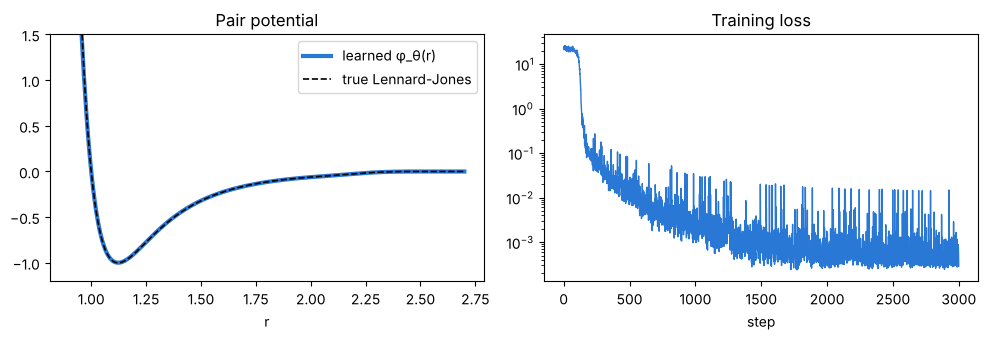

In [6]:
r = jnp.linspace(0.9, 2.7, 300)
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.5))
a.plot(r, jax.vmap(model.pair)(r), color=BLUE, lw=3, label="learned φ_θ(r)")
a.plot(r, lj.pair(r), "--", color="k", lw=1.2, label="true Lennard-Jones")
a.set_ylim(-1.2, 1.5)
a.set_xlabel("r")
a.legend()
a.set_title("Pair potential")
b.semilogy(losses, color=BLUE, lw=1)
b.set_xlabel("step")
b.set_title("Training loss")
plt.tight_layout()
plt.show()

## 5. Integrate the learned forces

The same velocity-Verlet + `lax.scan` integrator, given `F = −∇V_θ` instead of the true force. Here it runs 40,000 steps.

In [7]:
def learned_force(q):
    return em.forces(model.energy, q)


def true_force(q):
    return em.forces(lj, q)


start = em.initial_state(jax.random.PRNGKey(7))
traj_ml = em.simulate(learned_force, start, dt=0.005, n_steps=40_000, save_every=50)
traj_true = em.simulate(true_force, start, dt=0.005, n_steps=40_000, save_every=50)

E = em.total_energy(model.energy, traj_ml)
print("relative energy drift (learned V):", float(jnp.abs(E - E[0]).max() / abs(E[0])))
print("max |total momentum|:            ", float(jnp.abs(em.total_momentum(traj_ml.p)).max()))
print("max |angular momentum|:          ", float(jnp.abs(em.angular_momentum(traj_ml.q, traj_ml.p)).max()))

relative energy drift (learned V): 6.510141506586193e-05
max |total momentum|:             2.6867397195928788e-14
max |angular momentum|:           5.773159728050814e-14


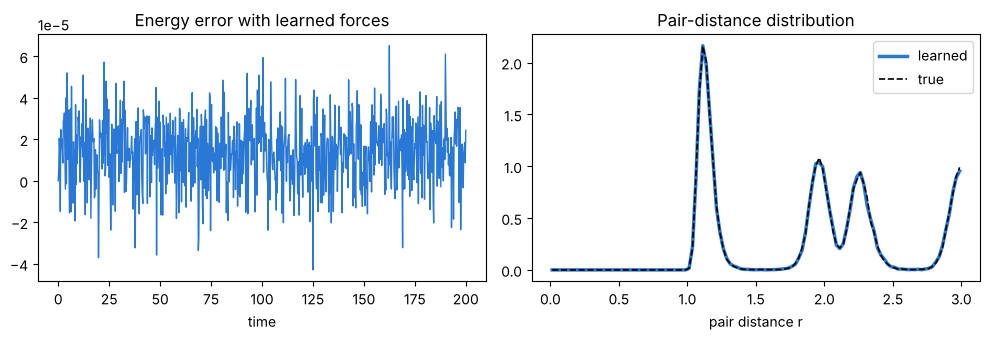

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.5))
a.plot(traj_ml.t, (E - E[0]) / abs(E[0]), color=BLUE, lw=1)
a.set_xlabel("time")
a.set_title("Energy error with learned forces")
for tr, c, ls, lw, lab in [(traj_ml, BLUE, "-", 2.5, "learned"), (traj_true, "k", "--", 1.2, "true")]:
    rr, dens = em.radial_distribution(tr.q[50:])
    b.plot(rr, dens, color=c, ls=ls, lw=lw, label=lab)
b.set_xlabel("pair distance r")
b.set_title("Pair-distance distribution")
b.legend()
plt.tight_layout()
plt.show()

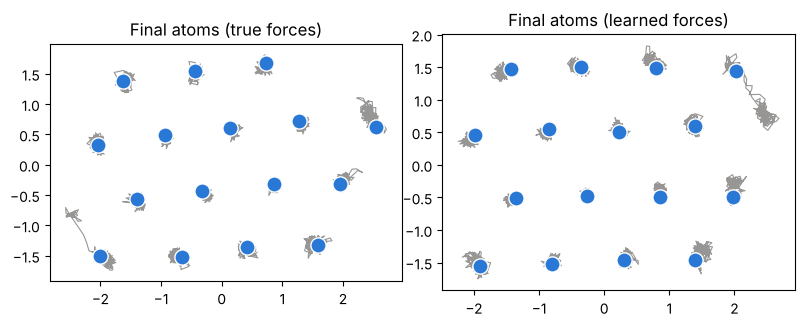

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, tr, title in [(axes[0], traj_true, "true forces"), (axes[1], traj_ml, "learned forces")]:
    for i in range(tr.q.shape[1]):
        ax.plot(tr.q[-200:, i, 0], tr.q[-200:, i, 1], lw=0.8, color=GRAY, alpha=0.6)
    ax.scatter(tr.q[-1, :, 0], tr.q[-1, :, 1], s=120, color=BLUE, edgecolor="white", zorder=3)
    ax.set_aspect("equal")
    ax.set_title(f"Final atoms ({title})")
plt.tight_layout()
plt.show()

The two runs end in different places. MD is chaotic, so any tiny force error eventually changes the exact path. What matters is that the learned run is **statistically** the same system: same energy behaviour, same structure (previous plot).

## 6. Save and reload the model

Equinox models are pytrees, so their weights can be serialised directly.

In [10]:
eqx.tree_serialise_leaves("my_potential.eqx", model)
skeleton = em.PairPotentialMLP(width=48, depth=2, key=jax.random.PRNGKey(0))
reloaded = eqx.tree_deserialise_leaves("my_potential.eqx", skeleton)
print("same energy after reload:", bool(reloaded.energy(q) == model.energy(q)))

same energy after reload: True


## 7. Things to try

- Train for fewer steps (`steps=500`) and see how energy conservation and structure degrade.
- Change the data temperature: `em.generate_dataset(key, temperature=0.6)`. A hotter cluster explores closer distances.
- Swap in a baseline: `em.DirectForceMLP(16, key=...)` predicts forces directly, with no energy. Simulate it and watch the energy (see `examples/baselines.py`).
- Learn a different potential: write any `φ(r)`, wrap it as `lambda q: em.pairwise_sum(φ, q)`, and pass it to `generate_dataset(..., potential=...)`.